:::{admonition} Download
:class: important

Download this notebook: **{nb-download}`intro.ipynb`**!

:::

In [1]:
%matplotlib inline
import warnings

# Ignore the first specific warning
warnings.filterwarnings(
    "ignore",
    message="plotting functions contained within `_documentation_utils` are intended for nemos's documentation.",
    category=UserWarning,
)

# Ignore the second specific warning
warnings.filterwarnings(
    "ignore",
    message="Ignoring cached namespace 'core'",
    category=UserWarning,
)

warnings.filterwarnings(
    "ignore",
    message=(
        "invalid value encountered in div "
    ),
    category=RuntimeWarning,
)

(glm_intro_background)=
# Generalized Linear Models

This page explains the simplest GLM in neuroscience: the linear-nonlinear-Poisson (LNP) model. In this model, the firing rate of a neuron at time $t$ depends only on the input at time $t$. The [last section](glm-intro-more-general) lists extensions of this model.

```{contents}
:local:
:depth: 2
```

## GLM components

The LNP model has three steps.

<figure markdown>
<!-- note that the src here has an extra ../ compared to other images, necessary when specifying path directly in html -->
<img src="../../../_static/lnp_model.svg" style="width: 100%", alt="Linear-Non Linear-Poisson illustration."/>
<figcaption>LNP model schematic. Modified from Pillow et al., 2008.</figcaption>
</figure>

1. A linear transformation of the input.
2. A nonlinearity that gives the *firing rate*.
3. A Poisson process with the firing rate as its mean, which generates *spikes*.

### Linear step

The linear transformation scales and shifts the input feature(s): $ \boldsymbol{W X} + \boldsymbol{c} $. In the one-dimensional case, this is a multiplication by a constant plus an intercept.

In the 1-d case, the model has two parameters. The weight $w$ scales the input. The intercept $c$ shifts the input. The linear step computes:

$$
L(x(t)) = w x(t) + c \tag{1}
$$

The next plots show the three steps for three example neurons. Each neuron has a different value of $w$ and $c$.

In [2]:
import matplotlib.pyplot as plt

# first import things
import numpy as np
import pynapple as nap

import nemos as nmo

# some helper plotting functions
from nemos import _documentation_utils as doc_plots

# configure plots some
plt.style.use(nmo.styles.plot_style)

The first plot shows the linear transformation of the input $x$:

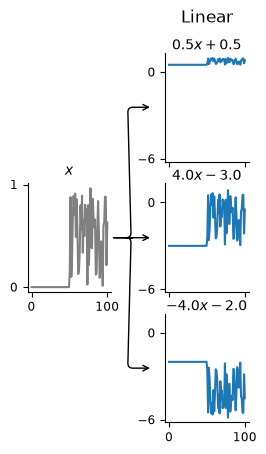

In [3]:
weights = np.asarray([.5, 4, -4])
intercepts = np.asarray([.5, -3, -2])

# make a step function with some noise riding on top
input_feature = np.zeros(100)
input_feature[50:] = 1
input_feature *= np.random.rand(100)
input_feature = nap.Tsd(np.linspace(0, 100, 100), input_feature)

fig = doc_plots.lnp_schematic(input_feature, weights, intercepts)

The weight stretches or shrinks the input. The intercept moves the baseline up or down. The model predicts the firing rate, so the intercept sets the baseline firing rate: the rate when the input is zero.

### Nonlinear step

The output of the linear step can be negative, but a firing rate cannot be negative. The nonlinearity makes the firing rate positive. To show this step, set `plot_nonlinear=True` in `lnp_schematic()`:

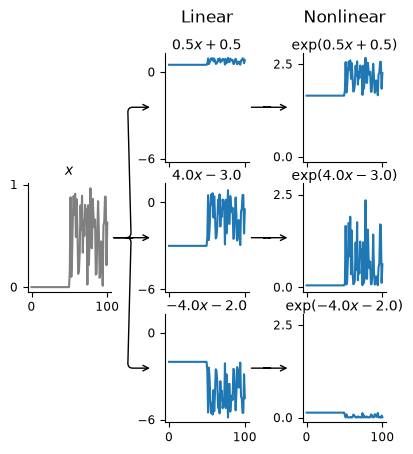

In [4]:
fig = doc_plots.lnp_schematic(input_feature, weights, intercepts,
                              plot_nonlinear=True)

:::{note}
NeMoS keeps the nonlinearity fixed. The default is the exponential.
A small number of other choices, such as soft-plus, are also available.
Each of these choices makes the firing rate non-negative and keeps the
problem convex. A convex problem has a single optimal solution. A more
complex nonlinearity is possible in principle, but convexity is not
guaranteed in general.
:::

With the exponential nonlinearity, the firing rate is:

$$
\lambda (t) = \exp (L(x(t))) = \exp (w x(t) + c) \tag{2}
$$

The output of the nonlinearity is always positive. Note that the scale of the y-axis also changes.

### Poisson step

The last step generates spikes from the firing rate:

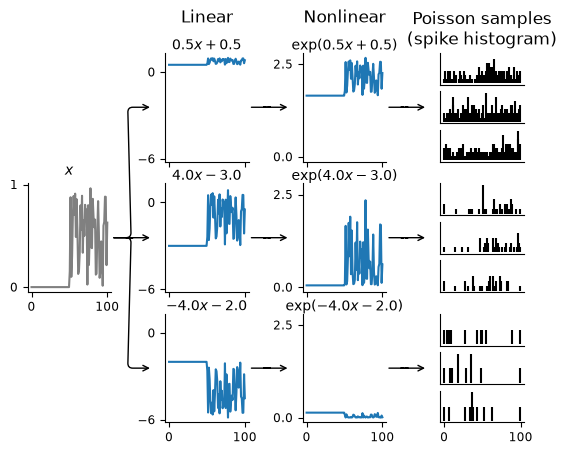

In [5]:
# mkdocs_gallery_thumbnail_number = 3
fig = doc_plots.lnp_schematic(input_feature, weights, intercepts,
                              plot_nonlinear=True, plot_spikes=True)

Spiking is a stochastic process. One firing rate can generate many different spike trains. The plot shows three spike trains for each neuron. Each spike train is a sample from a Poisson process. The mean of this process is the firing rate, that is, the output of the linear and nonlinear steps.

### Log-likelihood

The model can generate many spike trains, but the data contain one observed spike train. To compare the model with the data, use the _log-likelihood_. The log-likelihood measures how probable the observed spike train is for a given firing rate. If $y(t)$ is the spike count and $\lambda(t)$ is the firing rate, the log-likelihood is:

$$ \sum_t \log P(y(t) | \lambda(t)) = \sum_t y(t) \log(\lambda(t)) -
\lambda(t) - \log (y(t)!)\tag{3}$$

The $\log(y(t)!)$ term does not depend on $\lambda(t)$, so it does not change with the model. This term is usually dropped:

$$ \sum_t \log P(y(t) | \lambda(t)) \propto \sum_t y(t) \log(\lambda(t)) -
\lambda(t)\tag{4}$$

Equation (4) is the objective function of the GLM. The fit finds the firing rate that maximizes the likelihood of the observed spike train.

:::{note}

In NeMoS, the `score` method computes the log-likelihood from the
predictors and the counts. The method first computes the rate
$\lambda(t)$ with equation (2). Then it computes the likelihood with
equation (4). The optimization also uses this method.

:::

(glm-intro-more-general)=
## More general GLMs

The LNP model is a special case of a GLM. It has known limitations[$^{[1]}$](#ref-1). For example, the LNP model ignores the refractory period and other effects of spike history. Other pages show how to add _spike history filters_ to a GLM to get more accurate results. For a population of neurons recorded at the same time, a GLM can also include _coupling filters_ between neurons. Coupling filters can help show how much of the activity comes from the input $X$, and how much comes from the other neurons in the population.

## References
(ref-1)=
[1] [Pillow, JW, Shlens, J, Paninski, L, Sher, A,  Litke, AM, Chichilnisky, EJ, Simoncelli, EP (2008),  "Spatio-temporal correlations and visual signalling in a complete neuronal population." Nature 454: 995-9.](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC2684455/)